# Feature Store + ML Pipeline

Uses `athletes.csv` to predict deadlift weight

**Tools:** MLflow, Feast, Random Forest, CodeCarbon.



In [1]:
import sys
print(sys.version)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [2]:
%pip install --only-binary=numpy feast==0.49.0 mlflow==2.22.0 codecarbon==3.0.2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.6 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of uvicorn-worker to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.1/610.1 kB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 81.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 431.7/431.7 kB 27.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.4/270.4 kB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 

## 1. Set up the pipeline



In [1]:
import argparse
import hashlib
import json
import os
from pathlib import Path
from datetime import timedelta
import time
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
from feast import Entity, FeatureStore, FeatureView, Field, FileSource
from feast.types import Float32
from feast import ValueType
from codecarbon import OfflineEmissionsTracker
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split


ROOT = Path("/content/athletes_project")
ROOT.mkdir(parents=True, exist_ok=True)

BASE_FEATURES = ["age", "height", "weight", "is_male"]
EXTENDED_FEATURES = BASE_FEATURES + ["bmi", "weight_height_ratio", "age_squared"]

FEATURE_VERSIONS = {"v1": BASE_FEATURES, "v2": EXTENDED_FEATURES}
MODEL_SETTINGS = {
    "h1": {"n_estimators": 50, "max_depth": 6},
    "h2": {"n_estimators": 100, "max_depth": 12},
}

/usr/local/lib/python3.12/dist-packages/codecarbon/core/gpu.py:4: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Upload athletes.csv



In [2]:
from google.colab import files

uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if len(csv_files) != 1:
    raise ValueError("Upload exactly one athletes CSV.")

DATA_PATH = ROOT / "data" / "athletes.csv"
DATA_PATH.parent.mkdir(exist_ok=True)
DATA_PATH.write_bytes(uploaded[csv_files[0]])
del uploaded
print(f"Saved: {DATA_PATH.name}")

Saving athletes.csv to athletes (1).csv
Saved: athletes.csv


## 2. Clean the data and create two feature versions



| Version | Features |
|---|---|
| V1 | Age, height, weight, male indicator |
| V2 | V1 + BMI, weight/height ratio, age squared |

Deadlift is the target and is excluded from both versions. BMI assumes pounds and inches.

In [3]:
"""Clean athletes.csv using the assignment's steps."""

import numpy as np


def clean_data(data):
    # Remove rows with missing required values.
    data = data.dropna(
        subset=[
            "region",
            "age",
            "weight",
            "height",
            "howlong",
            "gender",
            "eat",
            "train",
            "background",
            "experience",
            "schedule",
            "deadlift",
            "candj",
            "snatch",
            "backsq",
        ]
    )

    # Remove columns we do not need.
    data = data.drop(
        columns=[
            "affiliate",
            "team",
            "name",
            "athlete_id",
            "fran",
            "helen",
            "grace",
            "filthy50",
            "fgonebad",
            "run400",
            "run5k",
            "pullups",
            "train",
        ]
    )

    # Remove outliers.
    data = data[data["weight"] < 1500]
    data = data[data["gender"] != "--"]
    data = data[data["age"] >= 18]
    data = data[(data["height"] < 96) & (data["height"] > 48)]

    # Changed the undefined v2 reference to data. Filter logic is unchanged.
    data = data[
        ((data["deadlift"] > 0) & (data["deadlift"] <= 1105))
        | ((data["gender"] == "Female") & (data["deadlift"] <= 636))
    ]
    data = data[(data["candj"] > 0) & (data["candj"] <= 395)]
    data = data[(data["snatch"] > 0) & (data["snatch"] <= 496)]
    data = data[(data["backsq"] > 0) & (data["backsq"] <= 1069)]

    # Clean survey data.
    decline_dict = {"Decline to answer|": np.nan}
    data = data.replace(decline_dict)
    data = data.dropna(
        subset=["background", "experience", "schedule", "howlong", "eat"]
    )
    return data.copy()


In [4]:
def load_and_prepare_data(path, out):
    raw = pd.read_csv(path)
    # 1. Use the assignment's cleaning code.
    data = clean_data(raw).reset_index(drop=True)

    # Feast needs a unique key. This is a new row ID, not the dropped athlete ID.
    data["row_id"] = np.arange(len(data), dtype="int64")

    # 2. Create the two feature versions.
    data["is_male"] = (data.gender == "Male").astype("float32")
    data["bmi"] = 703 * data.weight / data.height**2
    data["weight_height_ratio"] = data.weight / data.height
    data["age_squared"] = data.age**2
    data[EXTENDED_FEATURES] = data[EXTENDED_FEATURES].astype("float32")
    # Dataset has no observation dates: synthetic snapshot dates only, not temporal validation.
    data["event_timestamp"] = pd.Timestamp("2020-01-01", tz="UTC")
    report = {
        "raw_rows": len(raw),
        "clean_rows": len(data),
        "removed_rows": len(raw) - len(data),
        "input_sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
    }
    (out / "cleaning.json").write_text(json.dumps(report, indent=2))
    return data, report

## 3. Use Feast with the pipeline

Feast registers `athlete_v1` and `athlete_v2` and reads their Parquet snapshots through `get_historical_features()`.

The original athlete ID is dropped by the cleaning code. Feast uses a new row ID. Snapshot dates are placeholders because the CSV has no observation dates; this is not time-based validation.

In [5]:
def create_feature_store(data, repo, out):
    """Save both feature versions and register them in Feast."""
    (repo / "data").mkdir(parents=True, exist_ok=True)
    (repo / "feature_store.yaml").write_text("""project: athletes
provider: local
registry: registry.db
offline_store:
  type: file
online_store:
  type: sqlite
  path: online.db
entity_key_serialization_version: 3
""")
    store = FeatureStore(repo_path=str(repo))
    entity = Entity(name="athlete", join_keys=["row_id"], value_type=ValueType.INT64)
    views = []
    for version, names in FEATURE_VERSIONS.items():
        file = repo / "data" / f"{version}.parquet"
        data[["row_id", "event_timestamp"] + names].to_parquet(file, index=False)
        source = FileSource(path=str(file), timestamp_field="event_timestamp")
        view = FeatureView(
            name=f"athlete_{version}",
            entities=[entity],
            ttl=timedelta(days=365),
            schema=[Field(name=name, dtype=Float32) for name in names],
            source=source,
            online=True,
            tags={"version": version},
        )
        views.append(view)
    store.apply([entity] + views)
    (out / "feature_versions.json").write_text(json.dumps(FEATURE_VERSIONS, indent=2))
    return store

In [6]:
def retrieve_training_data(store, data, version, names):
    """Read features through Feast, then attach the target by row ID."""
    entities = data[["row_id"]].copy()
    entities["event_timestamp"] = pd.Timestamp("2020-01-02", tz="UTC")
    features = store.get_historical_features(
        entity_df=entities,
        features=[f"athlete_{version}:{name}" for name in names],
    ).to_df()
    training_data = features.merge(
        data[["row_id", "deadlift"]], on="row_id", validate="one_to_one"
    ).set_index("row_id")
    if training_data[names].isna().any().any():
        raise ValueError("Feast returned missing feature values.")
    return training_data

## 4. Run four experiments

Each run uses RandomForestRegressor, seed 42, one CPU worker, and the same 80/20 row split.

| Setting | Trees | Maximum depth |
|---|---:|---:|
| H1 | 50 | 6 |
| H2 | 100 | 12 |

Combinations: V1/H1, V1/H2, V2/H1, V2/H2. CodeCarbon measures fitting and prediction separately for each run.



In [7]:
def train_and_measure(
    Xtrain, Xtest, ytrain, ytest, version, names, config, label, country, out
):
    """Train one forest and log its accuracy and carbon estimate."""
    # Start a fresh emissions file for this run.
    (out / f"{label}_emissions.csv").unlink(missing_ok=True)
    tracker = OfflineEmissionsTracker(
        country_iso_code=country,
        project_name=label,
        output_dir=str(out),
        output_file=f"{label}_emissions.csv",
        measure_power_secs=1,
        tracking_mode="process",
        log_level="error",
    )
    tracker.start()
    start = time.perf_counter()
    try:
        model = RandomForestRegressor(**config, random_state=42, n_jobs=1)
        model.fit(Xtrain, ytrain)
        pred = model.predict(Xtest)
    finally:
        elapsed = time.perf_counter() - start
        emissions = tracker.stop()
    if emissions is None:
        raise RuntimeError("CodeCarbon returned no estimate; do not substitute zero.")
    metrics = {
        "mae": mean_absolute_error(ytest, pred),
        "rmse": np.sqrt(mean_squared_error(ytest, pred)),
        "r2": r2_score(ytest, pred),
        "carbon_kg": emissions,
        "fit_predict_seconds": elapsed,
    }
    baseline = np.repeat(ytrain.median(), len(ytest))
    metrics["baseline_mae"] = mean_absolute_error(ytest, baseline)
    mlflow.log_params(
        {
            "feature_version": version,
            "features": ",".join(names),
            **config,
            "random_state": 42,
            "n_jobs": 1,
            "country": country,
        }
    )
    mlflow.log_metrics(metrics)
    mlflow.sklearn.log_model(model, artifact_path="model", input_example=Xtrain.head(3))
    mlflow.log_artifact(str(out / f"{label}_emissions.csv"))
    return metrics, pred

### Define the plots and output files

In [8]:
def plot_predictions(axes, col, label, ytest, pred):
    """Show predictions and errors for one run."""
    axes[0, col].scatter(ytest, pred, s=3, alpha=0.1)
    axes[0, col].plot([20, 1200], [20, 1200], "r--")
    axes[0, col].set(
        xlabel="Actual deadlift (lb)", ylabel="Predicted (lb)", title=label
    )
    axes[1, col].scatter(pred, ytest - pred, s=3, alpha=0.1)
    axes[1, col].axhline(0, color="red", linestyle="--")
    axes[1, col].set(xlabel="Predicted (lb)", ylabel="Residual (lb)")

def save_comparison(rows, fig, out):
    """Save the four-run table and comparison plots."""
    # 6. Save the metrics and plots.
    fig.tight_layout()
    fig.savefig(out / "predictions_residuals.png", dpi=140)
    plt.close(fig)
    results = pd.DataFrame(rows)
    results.to_csv(out / "comparison.csv", index=False)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, metric in zip(axes, ["mae", "rmse", "carbon_kg"]):
        ax.bar(results.run, results[metric])
        ax.set_title(metric)
        ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    fig.savefig(out / "comparison.png", dpi=140)
    plt.close(fig)
    best = results.loc[results.mae.idxmin()]
    text = f"Lowest held-out MAE: {best['run']} ({best.mae:.2f} lb).\n\n"
    text += results.to_string(index=False) + "\n\n"
    text += (
        "Compare scatter points against the diagonal and residuals against zero. "
        "Systematic residual slopes indicate bias at the extremes. All runs use the same test rows. "
        "Use a new holdout to check the final model after choosing a run. "
        "Carbon estimates cover fit and predict only, not shared cleaning, Feast setup, plotting, or dependency installation. "
        "They are hardware and country dependent; short single runs are noisy and do not establish a reliable carbon ranking. "
        "Snapshot dates are synthetic. Self-reported data and plausibility filters limit generalization."
    )
    (out / "REPORT.txt").write_text(text)
    return results

In [9]:
def main(cli_args=None):
    parser = argparse.ArgumentParser()
    parser.add_argument("--data", type=Path, default=ROOT / "data/athletes.csv")
    parser.add_argument(
        "--country", default="USA", help="Country where this computer runs"
    )
    args = parser.parse_args(cli_args)
    data_path = args.data.resolve()
    os.chdir(ROOT)
    out = ROOT / "results"
    out.mkdir(exist_ok=True)
    mlflow.set_tracking_uri((ROOT / "mlruns").as_uri())
    mlflow.set_experiment("athletes-feature-store")

    with mlflow.start_run(run_name="full_pipeline"):
        # 1. Load and clean athletes.csv.
        data, cleaning = load_and_prepare_data(data_path, out)
        mlflow.log_params(cleaning)

        # 2. Register both feature versions in Feast.
        store = create_feature_store(data, ROOT / "feature_repo", out)

        # 3. Keep the same 80/20 split for every run.
        train_ids, test_ids = train_test_split(
            data["row_id"].to_numpy(), test_size=0.2, random_state=42
        )
        split = pd.DataFrame(
            {
                "row_id": data["row_id"],
                "split": np.where(data["row_id"].isin(test_ids), "test", "train"),
            }
        )
        split.to_csv(out / "split.csv", index=False)

        # 4. Run both settings for each feature version.
        rows = []
        fig, axes = plt.subplots(2, 4, figsize=(17, 8))
        column = 0
        for version, names in FEATURE_VERSIONS.items():
            training_data = retrieve_training_data(store, data, version, names)
            Xtrain = training_data.loc[train_ids, names]
            Xtest = training_data.loc[test_ids, names]
            ytrain = training_data.loc[train_ids, "deadlift"]
            ytest = training_data.loc[test_ids, "deadlift"]

            for setting, config in MODEL_SETTINGS.items():
                label = f"{version}_{setting}"
                with mlflow.start_run(run_name=label, nested=True):
                    metrics, predictions = train_and_measure(
                        Xtrain,
                        Xtest,
                        ytrain,
                        ytest,
                        version,
                        names,
                        config,
                        label,
                        args.country,
                        out,
                    )
                    rows.append({"run": label, **config, **metrics})
                    plot_predictions(axes, column, label, ytest, predictions)
                    column += 1

        # 5. Save metrics, model plots, and carbon comparisons.
        results = save_comparison(rows, fig, out)
        print(results.to_string(index=False))
        print(f"Saved results to {out}")
        mlflow.log_artifacts(str(out), artifact_path="comparison")

### Run the pipeline

In [10]:
COUNTRY = "USA"  # Assumed Colab host country; not verified.
main(["--data", str(DATA_PATH), "--country", COUNTRY])

2026/11/03 01:09:39 INFO mlflow.tracking.fluent: Experiment with name 'athletes-feature-store' does not exist. Creating a new experiment.
/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_fields.py:192: UserWarning: Field name "vector_enabled" in "SqliteOnlineStoreConfig" shadows an attribute in parent "VectorStoreConfig"
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/lo

  run  n_estimators  max_depth       mae      rmse       r2  carbon_kg  fit_predict_seconds  baseline_mae
v1_h1            50          6 46.192979 60.927267 0.606765   0.000004             0.738541     80.042791
v1_h2           100         12 46.613676 61.342290 0.601389   0.000019             3.445423     80.042791
v2_h1            50          6 45.917969 60.603626 0.610931   0.000008             1.510484     80.042791
v2_h2           100         12 46.391556 61.158564 0.603773   0.000031             5.826635     80.042791
Saved results to /content/athletes_project/results


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5. Compare model results


,run,n_estimators,max_depth,mae,rmse,r2,baseline_mae
0,v1_h1,50,6,46.193,60.927,0.607,80.043
1,v1_h2,100,12,46.614,61.342,0.601,80.043
2,v2_h1,50,6,45.918,60.604,0.611,80.043
3,v2_h2,100,12,46.392,61.159,0.604,80.043


Lowest MAE: v2_h1 — 45.92 lb


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


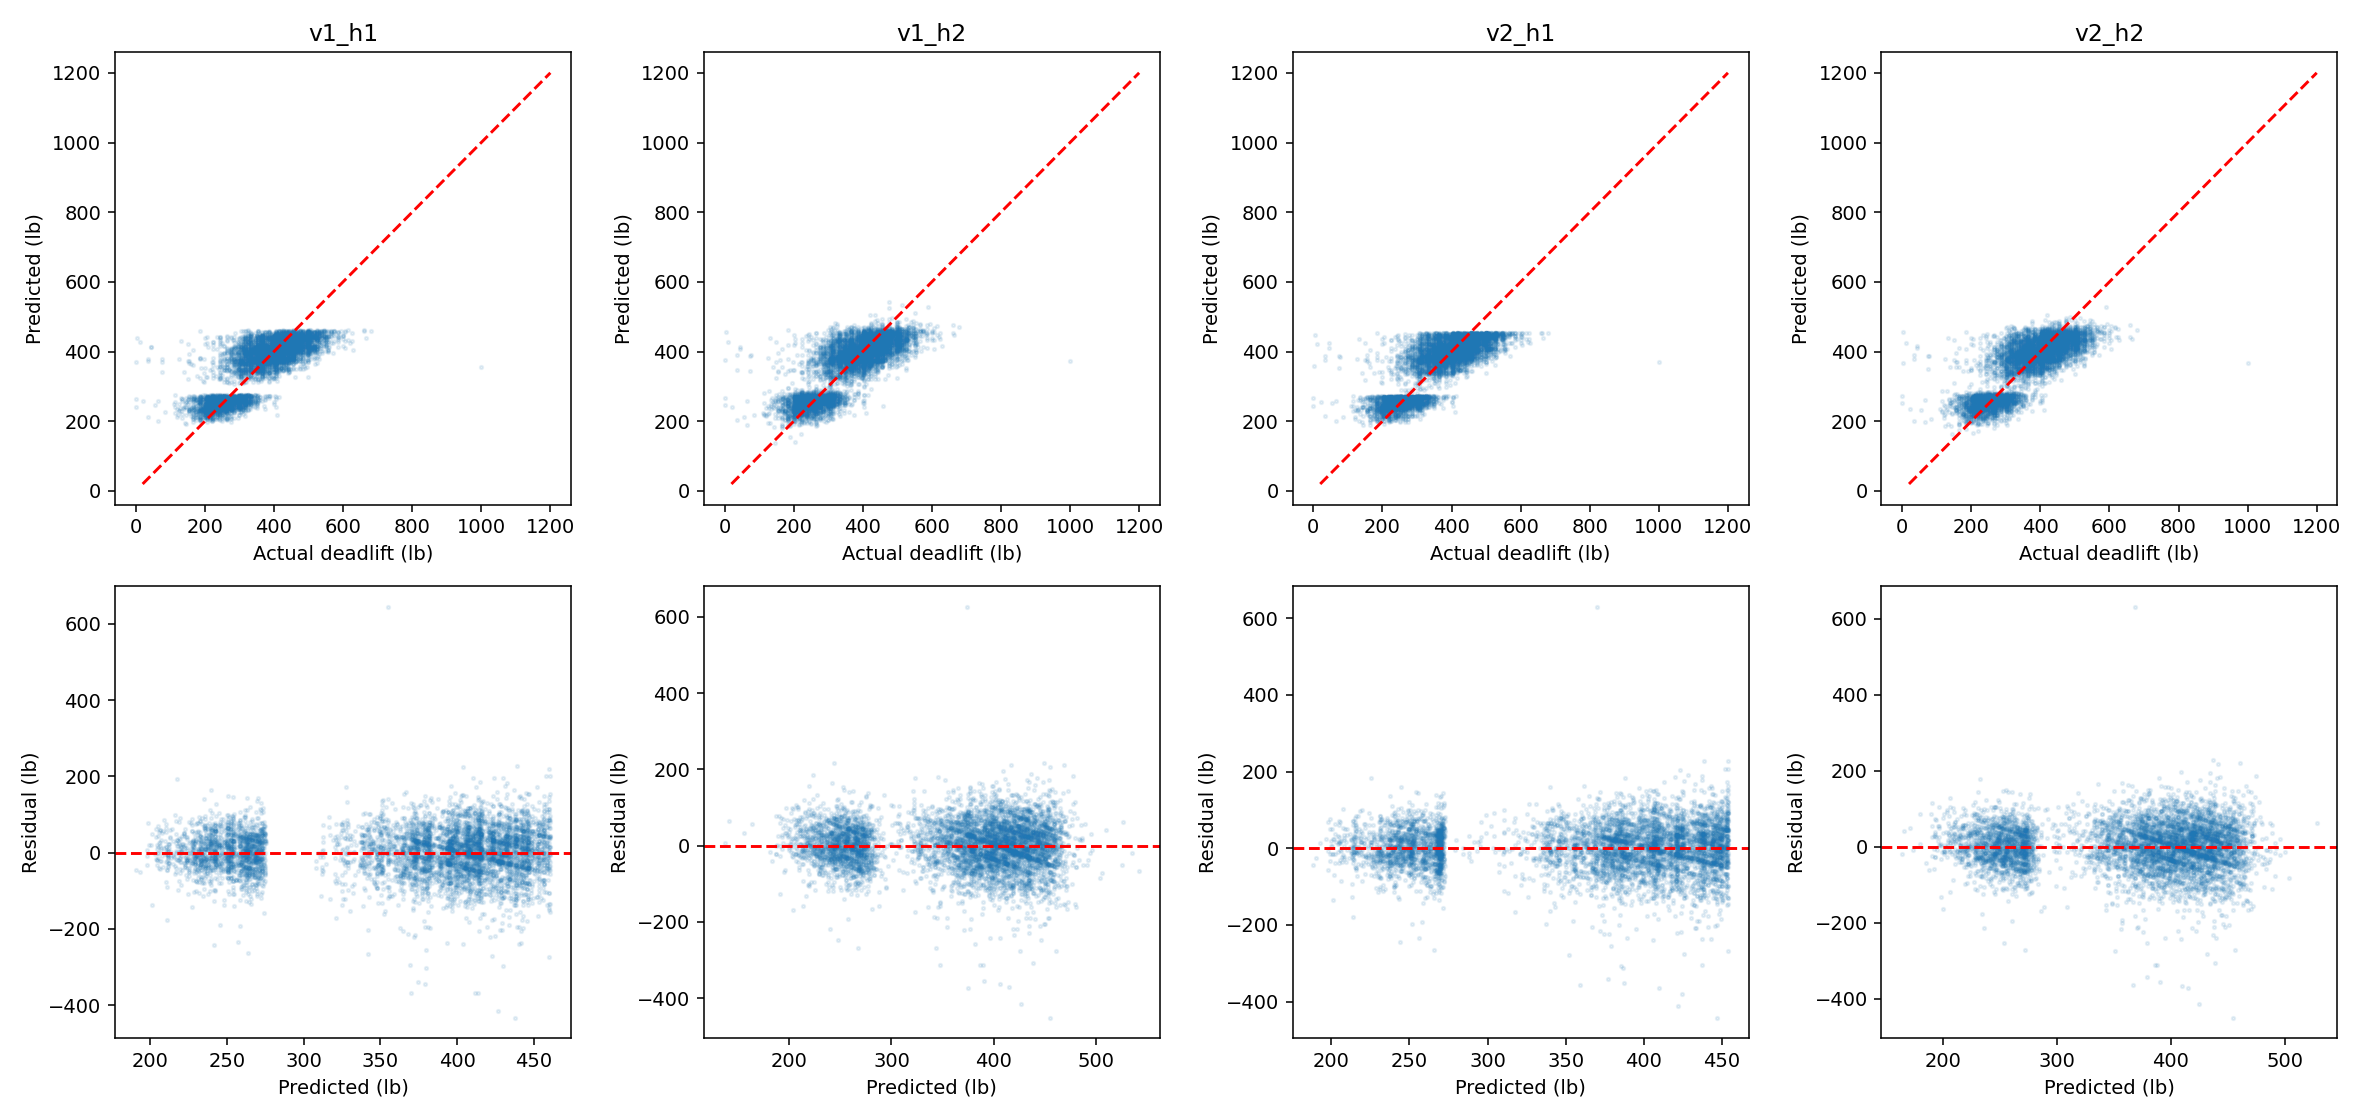

In [11]:
from IPython.display import display, Image, Markdown

results = pd.read_csv(ROOT / "results" / "comparison.csv")
display(results[["run", "n_estimators", "max_depth", "mae", "rmse", "r2", "baseline_mae"]].round(3))
best = results.loc[results["mae"].idxmin()]
print(f"Lowest MAE: {best['run']} — {best['mae']:.2f} lb")
display(Image(filename=str(ROOT / "results" / "predictions_residuals.png")))

### Plot observations

1. Diagonal Alignment:
All four models show a cluster following the red diagonal line well for average-range deadlifts (roughly 150 lb to 450 lb).
However, as deadlift weights exceed 500 lb, all models significantly underpredict performance, with predicted values flattening out and capping around 550 lb.

2. High Deadlifts:
High deadlift values (e.g., above 600 lb) are severely underpredicted across all configurations. This behavior is expected from Random Forest models, which cannot predict outside the range of the training target values and tend to predict towards the mean near the boundaries.

3. Residual Spread and Bias:
The residual plots demonstrate a distinct negative trend for higher actual values. This downward slope indicates systematic bias at the extremes: overprediction of very low deadlifts and severe underprediction of very high deadlifts.

4. Configuration Differences:
The v2 configurations (incorporating BMI, weight/height ratio, and age squared) show slightly lower Mean Absolute Error (MAE) compared to their v1 counterparts, indicating that these engineered features provide helpful non-linear signals. The shallower H1 models (max_depth=6) performed slightly better on the test set than the deeper H2 models, suggesting that the deeper trees may have slightly overfit the training data.

## 6. Compare carbon emissions



,run,estimated_co2_g,fit_predict_seconds
0,v1_h1,0.004031,0.738541
1,v1_h2,0.018550,3.445423
2,v2_h1,0.008145,1.510484
3,v2_h2,0.031386,5.826635


Lowest carbon estimate: v1_h1


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


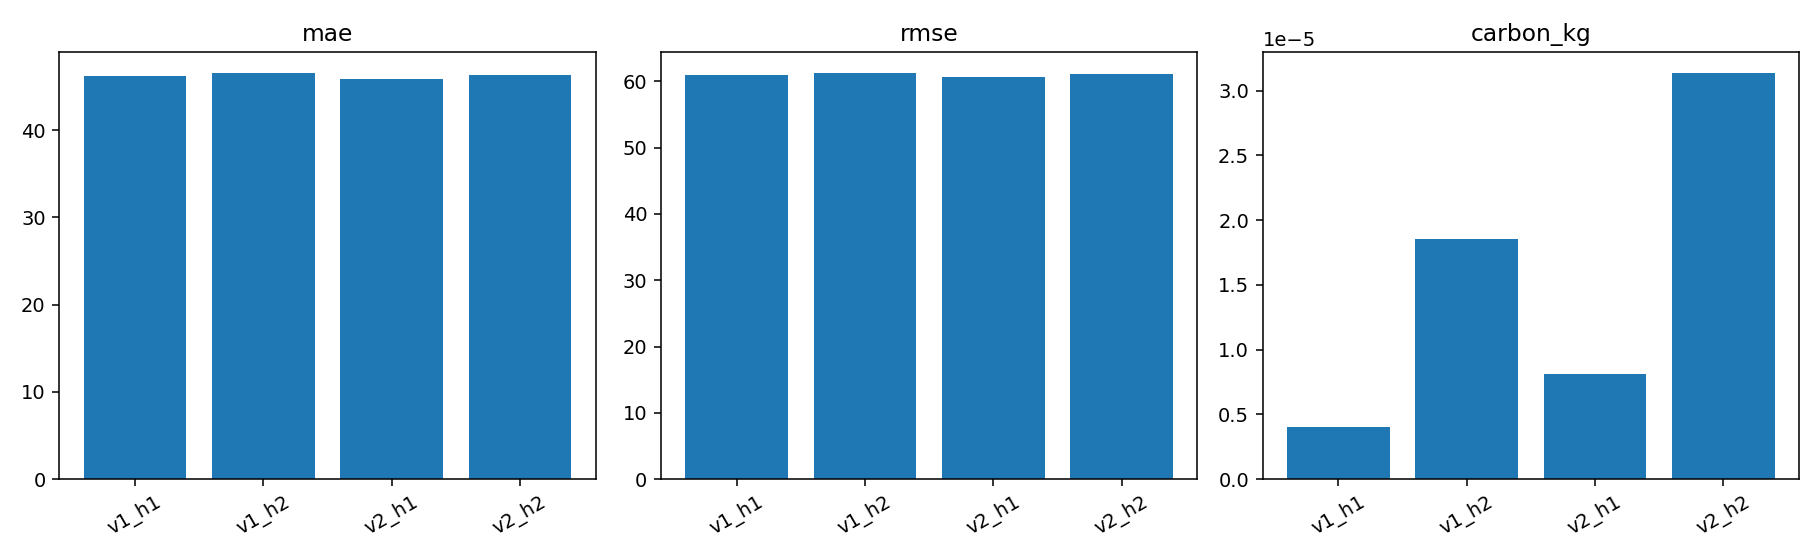

In [15]:
carbon = results[["run", "carbon_kg", "fit_predict_seconds"]].copy()
carbon["estimated_co2_g"] = carbon["carbon_kg"] * 1000
display(carbon[["run", "estimated_co2_g", "fit_predict_seconds"]])
lowest_carbon = results.loc[results["carbon_kg"].idxmin()]
print(f"Lowest carbon estimate: {lowest_carbon['run']}")
display(Image(filename=str(ROOT / "results" / "comparison.png")))